# Exp 1 - Application Problems (Section 1.5)
**Topic:** Spatial domain enhancement (High-Boost Filtering & Adaptive/Local Gamma Correction)

1. High-Boost Filtering
2. Adaptive Local Enhancement (local Gamma correction)

We use the classic **"cameraman"** test image (skimage `data.camera()`) instead of a flat/low-contrast
image. It has dark regions (coat, tripod), bright regions (sky) and fine detail (grass, buildings),
so the effect of each filter is clearly visible when compared to the original.

In [1]:
%pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

print("Everything is working!")

Everything is working!


Image shape: (512, 512) | min: 0.0 | max: 255.0 | mean: 129.06


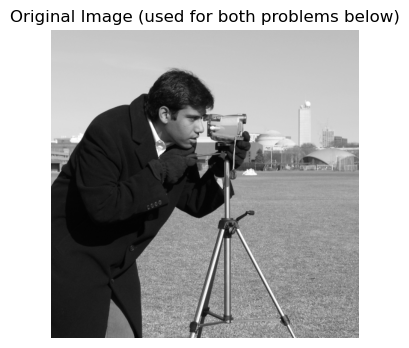

In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

# Load image
img = data.camera().astype(np.float32)

print("Image shape:", img.shape, "| min:", img.min(), 
      "| max:", img.max(), "| mean:", round(img.mean(), 2))

plt.figure(figsize=(4, 4))
plt.imshow(img.astype(np.uint8), cmap='gray')
plt.title('Original Image (used for both problems below)')
plt.axis('off')
plt.show()

## 1. High-Boost Filtering

$$f_{hb} = (A-1)f_{orig} + f_{sharpened}$$

**Idea:** A high-boost filter = original image + extra weight on the original + the sharpened
(edge-enhanced) version. It keeps the overall look of the image but boosts fine details/edges.
Larger `A` -> more of the original image is retained (less aggressive); values close to 1 push it
towards a plain sharpening filter.

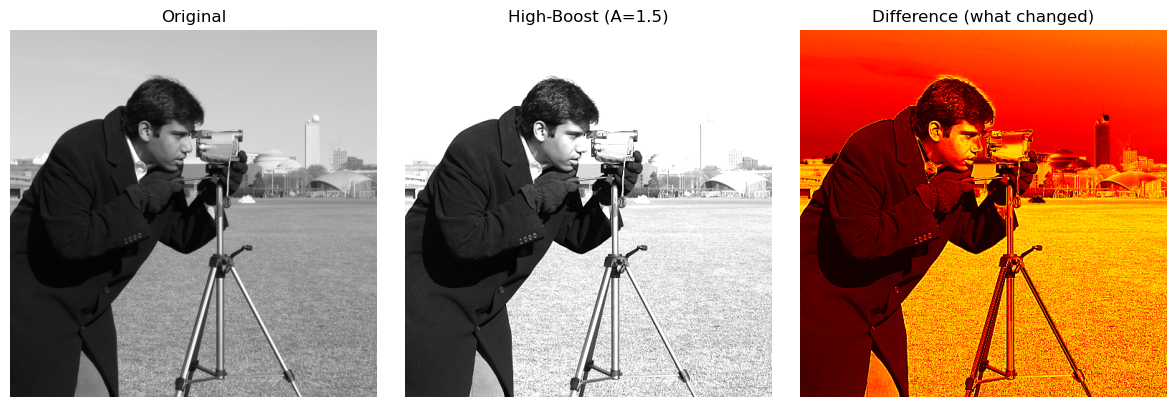

True

In [6]:
def high_boost_filter(f_orig, A=1.5):
    """
    Steps:
    1. Blur the image (low-pass filter) -> keeps only the smooth/low-frequency content.
    2. Subtract blurred from original -> what's left is the high-frequency detail (edges/texture).
    3. Add that detail back to the original -> this is normal 'unsharp masking' (sharpened image).
    4. Combine with the original using the High-Boost formula so we control how strong the
       sharpening is via the parameter A.
    """
    blurred = cv2.GaussianBlur(f_orig, (5, 5), 1.0)   # Step 1: low-pass (smoothed) version
    high_freq_mask = f_orig - blurred                  # Step 2: extract high-frequency detail
    sharpened = f_orig + high_freq_mask                 # Step 3: unsharp masking (basic sharpen)
    f_hb = (A - 1) * f_orig + sharpened                  # Step 4: high-boost formula
    return np.clip(f_hb, 0, 255).astype(np.uint8)        # keep pixel values valid (0-255)

hb_out = high_boost_filter(img, A=1.5)

# Absolute difference map: shows exactly WHERE and HOW MUCH the image changed.
# Brighter pixel here = bigger change from the original at that location.
hb_diff = cv2.absdiff(hb_out, img.astype(np.uint8))

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(img.astype(np.uint8), cmap='gray'); plt.title('Original'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(hb_out, cmap='gray'); plt.title('High-Boost (A=1.5)'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(hb_diff, cmap='hot'); plt.title('Difference (what changed)'); plt.axis('off')
plt.tight_layout()
plt.show()

cv2.imwrite('high_boost_output.jpg', hb_out)

## 2. Adaptive Local Enhancement

$$s = c \cdot r^{\gamma}$$

**Idea:** A single gamma value for the whole image can't fix an image that has both dark and bright
regions at the same time. Instead, we split the image into small blocks, look at each block's
average brightness, and pick a different gamma for that block:
- **Dark block** (mean < `dark_thresh`) -> use `gamma_dark` (< 1) to brighten it.
- **Bright block** (mean > `bright_thresh`) -> use `gamma_bright` (> 1) to darken/tone it down.
- **Mid-tone block** -> leave roughly as-is (`gamma_mid` = 1).

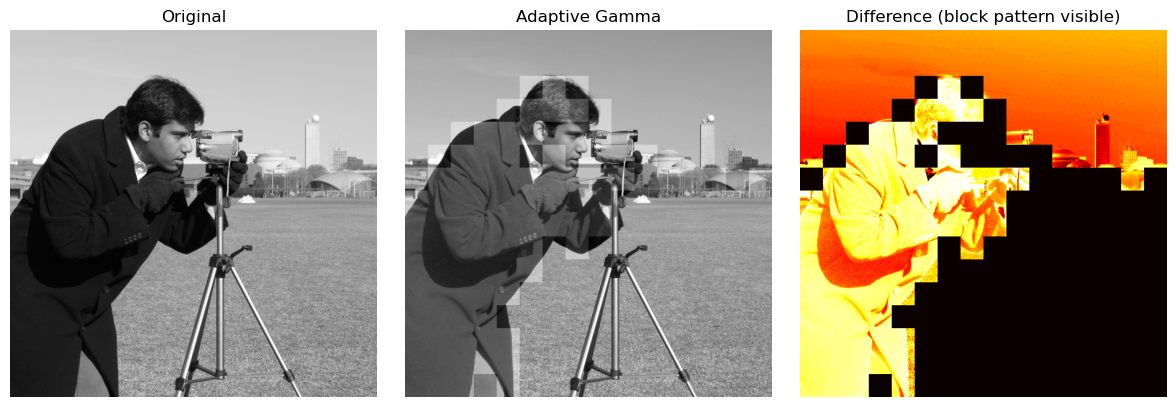

True

In [7]:
def adaptive_gamma_correction(f_orig, block_size=32,
                               dark_thresh=85, bright_thresh=170,
                               gamma_dark=0.5, gamma_mid=1.0, gamma_bright=1.8):
    f = f_orig.astype(np.float32)
    h, w = f.shape
    out = np.zeros_like(f)

    # Slide over the image in block_size x block_size chunks (non-overlapping grid)
    for y in range(0, h, block_size):
        for x in range(0, w, block_size):
            block = f[y:y+block_size, x:x+block_size]
            local_mean = np.mean(block)              # how dark/bright is THIS block

            # Choose the gamma for this block only, based on its own brightness
            if local_mean < dark_thresh:
                gamma = gamma_dark        # dark block -> brighten (gamma < 1)
            elif local_mean > bright_thresh:
                gamma = gamma_bright       # bright block -> compress highlights (gamma > 1)
            else:
                gamma = gamma_mid          # already balanced -> leave unchanged

            # Apply power-law (gamma) transform only to this block, write it into the output
            out[y:y+block_size, x:x+block_size] = 255.0 * (block / 255.0) ** gamma

    return np.clip(out, 0, 255).astype(np.uint8)

ag_out = adaptive_gamma_correction(img)

# Difference map: the blocky pattern here makes it obvious that DIFFERENT gamma values
# were applied to different regions (unlike a single global gamma, which would look uniform).
ag_diff = cv2.absdiff(ag_out, img.astype(np.uint8))

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(img.astype(np.uint8), cmap='gray'); plt.title('Original'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(ag_out, cmap='gray'); plt.title('Adaptive Gamma'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(ag_diff, cmap='hot'); plt.title('Difference (block pattern visible)'); plt.axis('off')
plt.tight_layout()
plt.show()

cv2.imwrite('adaptive_gamma_output.jpg', ag_out)